In [1]:
import pandas as pd
from pathlib import Path

h1 = pd.read_csv("data/raw/H1.csv")
h2 = pd.read_csv("data/raw/H2.csv")

print("H1:", h1.shape)
print("H2:", h2.shape)

display(h1.head())
display(h2.head())

H1: (40060, 31)
H2: (79330, 31)


,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,342,2015,July,27,1,0,0,2,0,...,No Deposit,NULL,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,0,737,2015,July,27,1,0,0,2,0,...,No Deposit,NULL,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,0,7,2015,July,27,1,0,1,1,0,...,No Deposit,NULL,NULL,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,0,13,2015,July,27,1,0,1,1,0,...,No Deposit,304,NULL,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,0,14,2015,July,27,1,0,2,2,0,...,No Deposit,240,NULL,0,Transient,98.0,0,1,Check-Out,2015-07-03


,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.0,...,No Deposit,6,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-03
1,1,88,2015,July,27,1,0,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-07-01
2,1,65,2015,July,27,1,0,4,1,0.0,...,No Deposit,9,NULL,0,Transient,68.0,0,1,Canceled,2015-04-30
3,1,92,2015,July,27,1,2,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,2,Canceled,2015-06-23
4,1,100,2015,July,27,2,0,2,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-04-02


In [2]:
# Combine the two hotel booking datasets
h1["HotelType"] = "Resort Hotel"
h2["HotelType"] = "City Hotel"

df = pd.concat([h1, h2], ignore_index=True)

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

display(df.head())

Total rows: 119390
Total columns: 32


,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate,HotelType
0,0,342,2015,July,27,1,0,0,2,0.0,...,NULL,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-01,Resort Hotel
1,0,737,2015,July,27,1,0,0,2,0.0,...,NULL,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-01,Resort Hotel
2,0,7,2015,July,27,1,0,1,1,0.0,...,NULL,NULL,0,Transient,75.0,0,0,Check-Out,2015-07-02,Resort Hotel
3,0,13,2015,July,27,1,0,1,1,0.0,...,304,NULL,0,Transient,75.0,0,0,Check-Out,2015-07-02,Resort Hotel
4,0,14,2015,July,27,1,0,2,2,0.0,...,240,NULL,0,Transient,98.0,0,1,Check-Out,2015-07-03,Resort Hotel


In [3]:
# Display column names and data types
print("Column names and data types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check identical rows
print("\nIdentical rows:")
print(df.duplicated().sum())

Column names and data types:
IsCanceled                       int64
LeadTime                         int64
ArrivalDateYear                  int64
ArrivalDateMonth                   str
ArrivalDateWeekNumber            int64
ArrivalDateDayOfMonth            int64
StaysInWeekendNights             int64
StaysInWeekNights                int64
Adults                           int64
Children                       float64
Babies                           int64
Meal                               str
Country                            str
MarketSegment                      str
DistributionChannel                str
IsRepeatedGuest                  int64
PreviousCancellations            int64
PreviousBookingsNotCanceled      int64
ReservedRoomType                   str
AssignedRoomType                   str
BookingChanges                   int64
DepositType                        str
Agent                              str
Company                            str
DaysInWaitingList                in

## Task 1: Dataset Understanding and Analytical Questions

### Dataset Information
- **Dataset:** Hotel Booking Demand Dataset
- **Source:** Supplementary data from the instructor-recommended research article
- **Article URL:** https://pmc.ncbi.nlm.nih.gov/articles/PMC6297060/
- **Files:** H1.csv and H2.csv
- **Format:** CSV
- **Total source records:** 119,390
- **Original columns:** 31 per file
- **Source grain:** One row represents one recorded hotel booking observation.
- **Candidate key:** No explicit booking ID is provided. A composite key using source file and original row number will be used to identify source records.

### Four Analytical Questions
1. How do cancellation rates compare between Resort Hotels and City Hotels?
2. How do average daily rates (ADR) change across arrival months for each hotel type?
3. Which market segments have the highest numbers of bookings?
4. How does the average lead time differ between canceled and non-canceled bookings across hotel types?

### Why This Dataset Is Interesting
This dataset contains individual hotel booking observations, allowing us to investigate booking behavior, cancellation patterns, room prices, and market segments. Unlike pre-aggregated statistics, it provides opportunities to validate records, handle missing values, and construct a dimensional model for analytical queries.

In [4]:
# Data dictionary for important analytical columns

data_dictionary = pd.DataFrame({
    "Column": [
        "HotelType",
        "IsCanceled",
        "LeadTime",
        "ArrivalDateYear",
        "ArrivalDateMonth",
        "MarketSegment",
        "ADR",
        "Adults",
        "Children",
        "Babies"
    ],
    "Expected Type": [
        "string", "integer", "integer", "integer",
        "string", "string", "float",
        "integer", "float", "integer"
    ],
    "Unit / Meaning": [
        "Hotel category: Resort or City",
        "Cancellation indicator: 1 = canceled, 0 = not canceled",
        "Days between booking entry and arrival",
        "Scheduled arrival year",
        "Scheduled arrival month",
        "Booking market segment",
        "Average daily room rate (monetary units)",
        "Number of adults",
        "Number of children",
        "Number of babies"
    ]
})

display(data_dictionary)

,Column,Expected Type,Unit / Meaning
0,HotelType,string,Hotel category: Resort or City
1,IsCanceled,integer,"Cancellation indicator: 1 = canceled, 0 = not ..."
2,LeadTime,integer,Days between booking entry and arrival
3,ArrivalDateYear,integer,Scheduled arrival year
4,ArrivalDateMonth,string,Scheduled arrival month
5,MarketSegment,string,Booking market segment
6,ADR,float,Average daily room rate (monetary units)
7,Adults,integer,Number of adults
8,Children,float,Number of children
9,Babies,integer,Number of babies


In [5]:
# Missing-value summary

missing_report = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (
        df.isna().mean() * 100
    ).round(2)
})

display(
    missing_report[
        missing_report["Missing Count"] > 0
    ].sort_values("Missing Count", ascending=False)
)

,Missing Count,Missing Percentage
Country,488,0.41
Children,4,0.00


## Task 2: Ingestion Strategy

**Ingestion approach:** Initial full load followed by incremental batch ingestion for future updates.

**Batch vs. Streaming:** Batch ingestion is appropriate because H1.csv and H2.csv are historical hotel booking datasets rather than continuously arriving real-time events.

**Pull vs. Push:** Pull-based ingestion is used because the pipeline reads the source CSV files from the local project directory.

**Ingestion frequency:** The initial historical dataset is loaded once. For future updates, a monthly batch schedule is proposed if new source files become available.

**Watermark:** The source file name and file checksum will be used to identify previously processed batches. The original row number within each file will identify individual source observations.

**Recovery and reruns:** The pipeline will record each load using a load ID. Reprocessing an unchanged file should not create duplicate Bronze records. Failed loads can be retried after checking the ingestion log.

**Justification:** This approach is suitable for historical booking data because it supports reproducibility, source traceability, and controlled ingestion without requiring real-time streaming infrastructure.

In [6]:
import duckdb

con = duckdb.connect("hotel_pipeline.duckdb")

con.execute("INSTALL ducklake;")
con.execute("LOAD ducklake;")

print("DuckDB and DuckLake are ready!")

DuckDB and DuckLake are ready!


## Task 3: Bronze Layer — Raw Data Ingestion

The Bronze layer preserves the original hotel booking records from H1.csv and H2.csv without applying cleaning transformations.

Each record will include ingestion metadata:
- source_name: Original CSV filename
- ingested_at: Timestamp when the record was loaded
- load_id: Identifier for the ingestion batch
- source_row_number: Original row position in the source file

The ingestion process will also record the number of rows loaded from each source file.

In [7]:
from pathlib import Path

# Create storage directory
Path("lakehouse_data").mkdir(exist_ok=True)

# Attach DuckLake catalog with local storage
con.execute("""
ATTACH 'ducklake:hotel_catalog.duckdb'
AS hotel_lake
(DATA_PATH 'lakehouse_data/');
""")

# Create Bronze, Silver, and Gold schemas
con.execute("CREATE SCHEMA IF NOT EXISTS hotel_lake.bronze;")
con.execute("CREATE SCHEMA IF NOT EXISTS hotel_lake.silver;")
con.execute("CREATE SCHEMA IF NOT EXISTS hotel_lake.gold;")

print("DuckLake attached successfully!")
print("Bronze, Silver, and Gold schemas created!")

DuckLake attached successfully!
Bronze, Silver, and Gold schemas created!


In [8]:
import hashlib
from datetime import datetime, timezone

# Prepare the original source files
source_files = [
    ("H1.csv", h1),
    ("H2.csv", h2)
]

bronze_batches = []

for filename, source_df in source_files:
    file_path = Path("data/raw") / filename

    # Generate a checksum for each source file
    checksum = hashlib.sha256(
        file_path.read_bytes()
    ).hexdigest()

    batch = source_df.drop(columns=["HotelType"], errors="ignore").copy()

    # Add ingestion metadata
    batch["source_name"] = filename
    batch["source_row_number"] = range(1, len(batch) + 1)
    batch["ingested_at"] = datetime.now(timezone.utc)
    batch["load_id"] = checksum[:16]

    bronze_batches.append(batch)

# Combine both batches
bronze_df = pd.concat(bronze_batches, ignore_index=True)

print("Prepared Bronze rows:", len(bronze_df))

# Register DataFrame with DuckDB
con.register("bronze_input", bronze_df)

# Create the Bronze table in DuckLake
con.execute("""
CREATE TABLE IF NOT EXISTS hotel_lake.bronze.hotel_bookings
AS SELECT * FROM bronze_input
WHERE 1 = 0
""")

# Avoid loading an unchanged file twice
for filename, _ in source_files:
    con.execute("""
        INSERT INTO hotel_lake.bronze.hotel_bookings
        SELECT *
        FROM bronze_input
        WHERE source_name = ?
          AND NOT EXISTS (
              SELECT 1
              FROM hotel_lake.bronze.hotel_bookings
              WHERE source_name = ?
                AND load_id = (
                    SELECT MIN(load_id)
                    FROM bronze_input
                    WHERE source_name = ?
                )
          )
    """, [filename, filename, filename])

print("Bronze ingestion completed!")

Prepared Bronze rows: 119390
Bronze ingestion completed!


In [9]:
# Check total records
total = con.execute("""
SELECT COUNT(*)
FROM hotel_lake.bronze.hotel_bookings
""").fetchone()[0]

print("Total Bronze records:", total)

# Check records by source file
report = con.execute("""
SELECT
    source_name,
    load_id,
    COUNT(*) AS input_rows,
    MIN(ingested_at) AS ingested_at
FROM hotel_lake.bronze.hotel_bookings
GROUP BY source_name, load_id
ORDER BY source_name
""").df()

display(report)

# Check uniqueness of source row identifiers
unique_count = con.execute("""
SELECT COUNT(*)
FROM (
    SELECT source_name, load_id, source_row_number
    FROM hotel_lake.bronze.hotel_bookings
    GROUP BY source_name, load_id, source_row_number
)
""").fetchone()[0]

print("Unique source identifiers:", unique_count)

assert total == 119390, "Unexpected Bronze row count"
assert unique_count == total, "Duplicate source identifiers detected"

print("Bronze validation passed!")

Total Bronze records: 119390


,source_name,load_id,input_rows,ingested_at
0,H1.csv,6f38fda13794fd6c,40060,2026-10-12 14:19:59.563900+03:00
1,H2.csv,5107090ffdc5585a,79330,2026-10-12 14:19:59.700552+03:00


Unique source identifiers: 119390
Bronze validation passed!


## Task 4: Silver Layer — Data Cleaning and Validation

The Silver layer transforms raw hotel booking records into validated, analysis-ready data.

The following quality rules will be applied:

1. Cancellation status must be either 0 or 1.
2. Lead time and number of guests cannot be negative.
3. The arrival date must be a valid calendar date.
4. ADR (Average Daily Rate) cannot be negative.
5. A booking must contain at least one guest.

Records failing these rules will be placed in a quarantine table with an explanation.

Missing Country values will be labeled "Unknown". Missing Children values will be treated as zero only for records that otherwise pass validation, and this assumption will be documented.

Identical-looking booking records will be retained because the dataset does not provide a unique booking ID. The source file and original row number will be used to distinguish observations.

In [10]:
# Inspect important columns before Silver cleaning

quality_checks = con.execute("""
SELECT
    COUNT(*) AS total_rows,
    SUM(CASE WHEN IsCanceled NOT IN (0, 1)
             OR IsCanceled IS NULL THEN 1 ELSE 0 END)
        AS invalid_cancellation,

    SUM(CASE WHEN LeadTime < 0 OR LeadTime IS NULL
             THEN 1 ELSE 0 END)
        AS invalid_lead_time,

    SUM(CASE WHEN ADR < 0 OR ADR IS NULL
             THEN 1 ELSE 0 END)
        AS invalid_adr,

    SUM(CASE WHEN Children IS NULL
             THEN 1 ELSE 0 END)
        AS missing_children,

    SUM(CASE WHEN Country IS NULL
             THEN 1 ELSE 0 END)
        AS missing_country,

    SUM(CASE WHEN Adults + COALESCE(Children, 0) + Babies <= 0
             THEN 1 ELSE 0 END)
        AS zero_guests

FROM hotel_lake.bronze.hotel_bookings
""").df()

display(quality_checks)

,total_rows,invalid_cancellation,invalid_lead_time,invalid_adr,missing_children,missing_country,zero_guests
0,119390,0.0,0.0,1.0,4.0,488.0,180.0


In [11]:
# Create a validated staging table with rejection reasons
con.execute("""
CREATE OR REPLACE TABLE hotel_lake.silver.booking_validation AS
SELECT *,
    CASE
        WHEN IsCanceled IS NULL OR IsCanceled NOT IN (0, 1)
            THEN 'Invalid cancellation status'
        WHEN LeadTime IS NULL OR LeadTime < 0
            THEN 'Invalid lead time'
        WHEN ADR IS NULL OR ADR < 0
            THEN 'Invalid ADR'
        WHEN Adults IS NULL OR Adults < 0
          OR Children < 0 OR Babies IS NULL OR Babies < 0
            THEN 'Invalid guest count'
        WHEN Adults + COALESCE(Children, 0) + Babies <= 0
            THEN 'No guests'
        WHEN TRY_CAST(
            CAST(ArrivalDateYear AS VARCHAR) || '-' ||
            CAST(
                CASE ArrivalDateMonth
                    WHEN 'January' THEN 1
                    WHEN 'February' THEN 2
                    WHEN 'March' THEN 3
                    WHEN 'April' THEN 4
                    WHEN 'May' THEN 5
                    WHEN 'June' THEN 6
                    WHEN 'July' THEN 7
                    WHEN 'August' THEN 8
                    WHEN 'September' THEN 9
                    WHEN 'October' THEN 10
                    WHEN 'November' THEN 11
                    WHEN 'December' THEN 12
                END AS VARCHAR
            ) || '-' ||
            CAST(ArrivalDateDayOfMonth AS VARCHAR)
            AS DATE
        ) IS NULL
            THEN 'Invalid arrival date'
        ELSE NULL
    END AS rejection_reason
FROM hotel_lake.bronze.hotel_bookings
""")

print("Validation staging table created!")

Validation staging table created!


In [12]:
con.execute("""
CREATE OR REPLACE TABLE hotel_lake.silver.quarantined_bookings AS
SELECT *
FROM hotel_lake.silver.booking_validation
WHERE rejection_reason IS NOT NULL
""")

quarantine_count = con.execute("""
SELECT COUNT(*)
FROM hotel_lake.silver.quarantined_bookings
""").fetchone()[0]

print("Quarantined records:", quarantine_count)

display(con.execute("""
SELECT rejection_reason, COUNT(*) AS records
FROM hotel_lake.silver.quarantined_bookings
GROUP BY rejection_reason
ORDER BY records DESC
""").df())

Quarantined records: 181


,rejection_reason,records
0,No guests,180
1,Invalid ADR,1


In [13]:
con.execute("""
CREATE OR REPLACE TABLE hotel_lake.silver.clean_bookings AS
SELECT
    * EXCLUDE (Country, Children, rejection_reason),

    COALESCE(NULLIF(TRIM(Country), ''), 'Unknown')
        AS Country,

    COALESCE(Children, 0)
        AS Children,

    StaysInWeekendNights + StaysInWeekNights
        AS TotalNights,

    Adults + COALESCE(Children, 0) + Babies
        AS TotalGuests

FROM hotel_lake.silver.booking_validation
WHERE rejection_reason IS NULL
""")

silver_count = con.execute("""
SELECT COUNT(*)
FROM hotel_lake.silver.clean_bookings
""").fetchone()[0]

print("Clean Silver records:", silver_count)
print("Quarantined records:", quarantine_count)

assert silver_count + quarantine_count == 119390

print("Silver reconciliation passed!")

Clean Silver records: 119209
Quarantined records: 181
Silver reconciliation passed!


### Silver Data Quality Report

This report summarizes the number of source records, validated records, quarantined records, missing values, duplicate-looking records, and source-key uniqueness.

The dataset does not contain an original booking ID. Therefore, identical-looking observations are reported but not automatically removed.

In [14]:
# Silver Data Quality Report

bronze_count = con.execute("""
SELECT COUNT(*)
FROM hotel_lake.bronze.hotel_bookings
""").fetchone()[0]

silver_count = con.execute("""
SELECT COUNT(*)
FROM hotel_lake.silver.clean_bookings
""").fetchone()[0]

quarantine_count = con.execute("""
SELECT COUNT(*)
FROM hotel_lake.silver.quarantined_bookings
""").fetchone()[0]

# Count missing values in original Bronze data
missing_values = con.execute("""
SELECT
    SUM(CASE WHEN Country IS NULL THEN 1 ELSE 0 END)
        AS missing_country,
    SUM(CASE WHEN Children IS NULL THEN 1 ELSE 0 END)
        AS missing_children
FROM hotel_lake.bronze.hotel_bookings
""").df()

# Check source-key uniqueness in Silver
unique_keys = con.execute("""
SELECT COUNT(*)
FROM (
    SELECT source_name, load_id, source_row_number
    FROM hotel_lake.silver.clean_bookings
    GROUP BY source_name, load_id, source_row_number
)
""").fetchone()[0]

quality_report = pd.DataFrame({
    "Metric": [
        "Bronze records",
        "Clean Silver records",
        "Quarantined records",
        "Identical-looking source rows",
        "Missing Country values in Bronze",
        "Missing Children values in Bronze",
        "Unique Silver source identifiers"
    ],
    "Count": [
        bronze_count,
        silver_count,
        quarantine_count,
        int(df.duplicated().sum()),
        int(missing_values["missing_country"].iloc[0]),
        int(missing_values["missing_children"].iloc[0]),
        unique_keys
    ]
})

display(quality_report)

assert bronze_count == silver_count + quarantine_count
assert unique_keys == silver_count

print("Silver quality checks passed!")

,Metric,Count
0,Bronze records,119390
1,Clean Silver records,119209
2,Quarantined records,181
3,Identical-looking source rows,31994
4,Missing Country values in Bronze,488
5,Missing Children values in Bronze,4
6,Unique Silver source identifiers,119209


Silver quality checks passed!


In [15]:
quarantine_report = con.execute("""
SELECT
    rejection_reason,
    COUNT(*) AS record_count
FROM hotel_lake.silver.quarantined_bookings
GROUP BY rejection_reason
ORDER BY record_count DESC
""").df()

display(quarantine_report)

,rejection_reason,record_count
0,No guests,180
1,Invalid ADR,1


## Task 5: Gold Layer — Dimensional Modeling

### Star Schema Design

The Gold layer uses a star schema to support hotel booking analytics.

**Fact table:** fact_bookings

Grain: One row per validated hotel booking observation.

Measures:
- Booking count (1 per observation)
- Cancellation indicator
- Lead time in days
- Average daily rate (ADR)
- Total nights
- Total guests

**Dimension tables:**
- dim_hotel: Hotel category
- dim_date: Scheduled arrival date
- dim_market_segment: Booking market segment

### Design Justification

The fact table contains numeric measures and foreign keys connecting to dimensions. The dimensions provide descriptive attributes for grouping and filtering.

A source-record identifier is retained for traceability. Identical-looking booking observations remain separate because the original dataset does not contain unique booking IDs.

In [16]:
con.execute("""
CREATE OR REPLACE TABLE hotel_lake.gold.dim_hotel AS
SELECT
    ROW_NUMBER() OVER (ORDER BY HotelType) AS hotel_key,
    HotelType AS hotel_type
FROM (
    SELECT DISTINCT
        CASE
            WHEN source_name = 'H1.csv' THEN 'Resort Hotel'
            WHEN source_name = 'H2.csv' THEN 'City Hotel'
        END AS HotelType
    FROM hotel_lake.silver.clean_bookings
)
""")

display(con.execute("""
SELECT * FROM hotel_lake.gold.dim_hotel
ORDER BY hotel_key
""").df())

,hotel_key,hotel_type
0,1,City Hotel
1,2,Resort Hotel


In [17]:
con.execute("""
CREATE OR REPLACE TABLE hotel_lake.gold.dim_market_segment AS
SELECT
    ROW_NUMBER() OVER (ORDER BY market_segment)
        AS market_segment_key,
    market_segment
FROM (
    SELECT DISTINCT
        COALESCE(NULLIF(TRIM(MarketSegment), ''), 'Unknown')
            AS market_segment
    FROM hotel_lake.silver.clean_bookings
)
""")

display(con.execute("""
SELECT * FROM hotel_lake.gold.dim_market_segment
ORDER BY market_segment_key
""").df())

,market_segment_key,market_segment
0,1,Aviation
1,2,Complementary
2,3,Corporate
3,4,Direct
4,5,Groups
5,6,Offline TA/TO
6,7,Online TA
7,8,Undefined


In [18]:
con.execute("""
CREATE OR REPLACE TABLE hotel_lake.gold.dim_date AS
WITH dates AS (
    SELECT DISTINCT
        MAKE_DATE(
            ArrivalDateYear,
            CASE ArrivalDateMonth
                WHEN 'January' THEN 1
                WHEN 'February' THEN 2
                WHEN 'March' THEN 3
                WHEN 'April' THEN 4
                WHEN 'May' THEN 5
                WHEN 'June' THEN 6
                WHEN 'July' THEN 7
                WHEN 'August' THEN 8
                WHEN 'September' THEN 9
                WHEN 'October' THEN 10
                WHEN 'November' THEN 11
                WHEN 'December' THEN 12
            END,
            ArrivalDateDayOfMonth
        ) AS arrival_date
    FROM hotel_lake.silver.clean_bookings
)
SELECT
    CAST(STRFTIME(arrival_date, '%Y%m%d') AS INTEGER)
        AS date_key,
    arrival_date,
    YEAR(arrival_date) AS year,
    MONTH(arrival_date) AS month_number,
    MONTHNAME(arrival_date) AS month_name,
    QUARTER(arrival_date) AS quarter
FROM dates
""")

display(con.execute("""
SELECT *
FROM hotel_lake.gold.dim_date
ORDER BY arrival_date
LIMIT 10
""").df())

,date_key,arrival_date,year,month_number,month_name,quarter
0,20150701,2015-07-01,2015,7,July,3
1,20150702,2015-07-02,2015,7,July,3
2,20150703,2015-07-03,2015,7,July,3
3,20150704,2015-07-04,2015,7,July,3
4,20150705,2015-07-05,2015,7,July,3
5,20150706,2015-07-06,2015,7,July,3
6,20150707,2015-07-07,2015,7,July,3
7,20150708,2015-07-08,2015,7,July,3
8,20150709,2015-07-09,2015,7,July,3
9,20150710,2015-07-10,2015,7,July,3


In [19]:
con.execute("""
CREATE OR REPLACE TABLE hotel_lake.gold.fact_bookings AS
SELECT
    s.source_name,
    s.load_id,
    s.source_row_number,

    h.hotel_key,
    d.date_key,
    m.market_segment_key,

    1 AS booking_count,
    s.IsCanceled AS is_canceled,
    s.LeadTime AS lead_time,
    s.ADR AS adr,
    s.TotalNights AS total_nights,
    s.TotalGuests AS total_guests

FROM hotel_lake.silver.clean_bookings s

JOIN hotel_lake.gold.dim_hotel h
    ON h.hotel_type =
        CASE
            WHEN s.source_name = 'H1.csv' THEN 'Resort Hotel'
            WHEN s.source_name = 'H2.csv' THEN 'City Hotel'
        END

JOIN hotel_lake.gold.dim_date d
    ON d.date_key = CAST(
        STRFTIME(
            MAKE_DATE(
                s.ArrivalDateYear,
                CASE s.ArrivalDateMonth
                    WHEN 'January' THEN 1
                    WHEN 'February' THEN 2
                    WHEN 'March' THEN 3
                    WHEN 'April' THEN 4
                    WHEN 'May' THEN 5
                    WHEN 'June' THEN 6
                    WHEN 'July' THEN 7
                    WHEN 'August' THEN 8
                    WHEN 'September' THEN 9
                    WHEN 'October' THEN 10
                    WHEN 'November' THEN 11
                    WHEN 'December' THEN 12
                END,
                s.ArrivalDateDayOfMonth
            ),
            '%Y%m%d'
        ) AS INTEGER
    )

JOIN hotel_lake.gold.dim_market_segment m
    ON m.market_segment =
        COALESCE(NULLIF(TRIM(s.MarketSegment), ''), 'Unknown')
""")

print("Gold fact table created successfully!")

Gold fact table created successfully!


In [20]:
gold_report = con.execute("""
SELECT
    (SELECT COUNT(*)
     FROM hotel_lake.silver.clean_bookings)
        AS silver_rows,

    (SELECT COUNT(*)
     FROM hotel_lake.gold.fact_bookings)
        AS gold_fact_rows,

    (SELECT COUNT(*)
     FROM hotel_lake.gold.dim_hotel)
        AS hotel_dimension_rows,

    (SELECT COUNT(*)
     FROM hotel_lake.gold.dim_date)
        AS date_dimension_rows,

    (SELECT COUNT(*)
     FROM hotel_lake.gold.dim_market_segment)
        AS market_segment_dimension_rows
""").df()

display(gold_report)

assert (
    gold_report["silver_rows"].iloc[0]
    == gold_report["gold_fact_rows"].iloc[0]
)

print("Gold row-count reconciliation passed!")

,silver_rows,gold_fact_rows,hotel_dimension_rows,date_dimension_rows,market_segment_dimension_rows
0,119209,119209,2,793,8


Gold row-count reconciliation passed!


### Gold Layer Integrity Validation

This section verifies that the Gold fact table has unique source-record identifiers and that all foreign keys match their corresponding dimension tables.


In [21]:
integrity_report = con.execute("""
SELECT
    COUNT(*) AS total_fact_rows,

    COUNT(DISTINCT (
        source_name, load_id, source_row_number
    )) AS unique_booking_records,

    SUM(CASE WHEN h.hotel_key IS NULL
        THEN 1 ELSE 0 END) AS invalid_hotel_keys,

    SUM(CASE WHEN d.date_key IS NULL
        THEN 1 ELSE 0 END) AS invalid_date_keys,

    SUM(CASE WHEN m.market_segment_key IS NULL
        THEN 1 ELSE 0 END) AS invalid_segment_keys

FROM hotel_lake.gold.fact_bookings f

LEFT JOIN hotel_lake.gold.dim_hotel h
    ON f.hotel_key = h.hotel_key

LEFT JOIN hotel_lake.gold.dim_date d
    ON f.date_key = d.date_key

LEFT JOIN hotel_lake.gold.dim_market_segment m
    ON f.market_segment_key = m.market_segment_key
""").df()

display(integrity_report)

assert integrity_report["total_fact_rows"].iloc[0] == 119209
assert integrity_report["unique_booking_records"].iloc[0] == 119209

for col in [
    "invalid_hotel_keys",
    "invalid_date_keys",
    "invalid_segment_keys"
]:
    assert integrity_report[col].iloc[0] == 0

print("Gold integrity validation passed!")

,total_fact_rows,unique_booking_records,invalid_hotel_keys,invalid_date_keys,invalid_segment_keys
0,119209,119209,0.0,0.0,0.0


Gold integrity validation passed!


## Task 6: Analytical Queries and Visualizations

### Query 1: Cancellation Rates by Hotel Type

**Business Question:** How do cancellation rates compare between Resort Hotels and City Hotels?

This query calculates the total number of bookings, canceled bookings, and cancellation percentage for each hotel type using the Gold star schema.

In [22]:
# Query 1: Cancellation rates by hotel type

query1 = con.execute("""
SELECT
    h.hotel_type,
    SUM(f.booking_count) AS total_bookings,
    SUM(f.is_canceled) AS canceled_bookings,
    ROUND(
        100.0 * SUM(f.is_canceled)
        / NULLIF(SUM(f.booking_count), 0),
        2
    ) AS cancellation_rate
FROM hotel_lake.gold.fact_bookings f
JOIN hotel_lake.gold.dim_hotel h
    ON f.hotel_key = h.hotel_key
GROUP BY h.hotel_type
ORDER BY cancellation_rate DESC
""").df()

display(query1)

,hotel_type,total_bookings,canceled_bookings,cancellation_rate
0,City Hotel,79163.0,33079.0,41.79
1,Resort Hotel,40046.0,11120.0,27.77


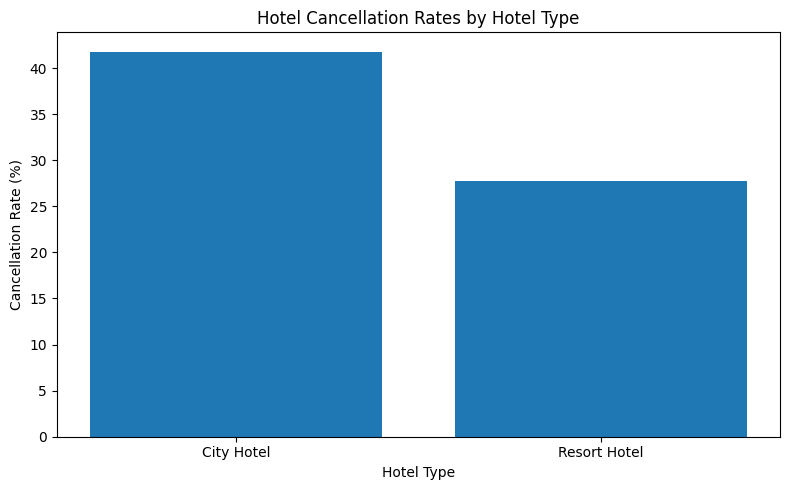

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    query1["hotel_type"],
    query1["cancellation_rate"]
)

plt.title("Hotel Cancellation Rates by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")

plt.tight_layout()
plt.show()

**Query 1 Finding:** City Hotels have a cancellation rate of 41.79%, compared with 27.77% for Resort Hotels. This indicates that City Hotels experience approximately 14 percentage points more cancellations, suggesting that cancellation management may be especially important for City Hotels.

### Query 2: Average Daily Rate by Month

**Business Question:** How do average daily rates (ADR) change across arrival months for each hotel type?

This query compares monthly average room rates between City Hotels and Resort Hotels.

**Method:** Calculate the average ADR for each hotel type and arrival month using the Gold fact table and dimension tables.

In [24]:
# Query 2: Average Daily Rate by Month

query2 = con.execute("""
SELECT
    h.hotel_type,
    d.month_number,
    d.month_name,
    ROUND(AVG(f.adr), 2) AS average_adr,
    COUNT(*) AS total_bookings

FROM hotel_lake.gold.fact_bookings f

JOIN hotel_lake.gold.dim_hotel h
    ON f.hotel_key = h.hotel_key

JOIN hotel_lake.gold.dim_date d
    ON f.date_key = d.date_key

GROUP BY
    h.hotel_type,
    d.month_number,
    d.month_name

ORDER BY
    d.month_number,
    h.hotel_type
""").df()

display(query2)

,hotel_type,month_number,month_name,average_adr,total_bookings
0,City Hotel,1,January,82.75,3730
1,Resort Hotel,1,January,49.51,2191
2,City Hotel,2,February,85.33,4950
3,Resort Hotel,2,February,55.19,3102
4,City Hotel,3,March,92.97,6434
5,Resort Hotel,3,March,57.57,3333
6,City Hotel,4,April,111.40,7469
7,Resort Hotel,4,April,77.85,3609
8,City Hotel,5,May,121.76,8221
9,Resort Hotel,5,May,78.76,3559


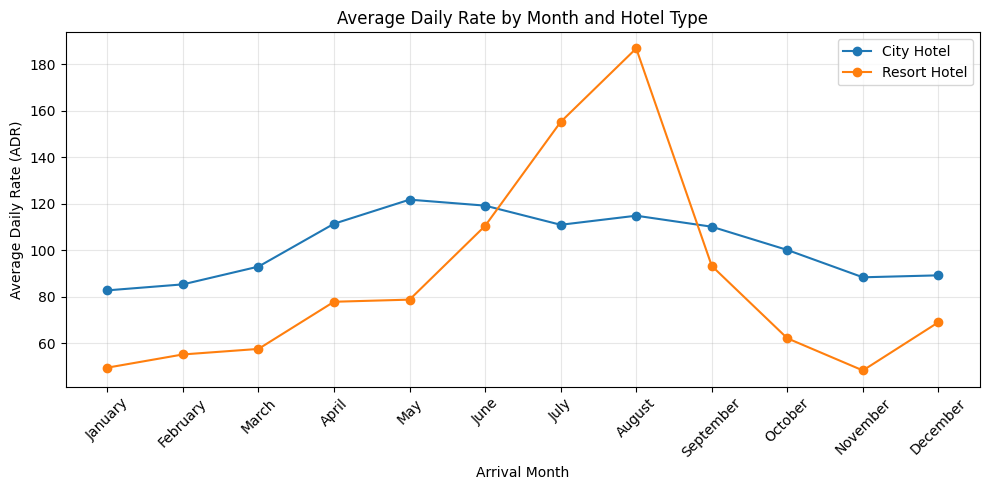

In [25]:
# Visualization 2: Monthly ADR Trends

plt.figure(figsize=(10, 5))

for hotel in query2["hotel_type"].unique():
    hotel_data = query2[
        query2["hotel_type"] == hotel
    ].sort_values("month_number")

    plt.plot(
        hotel_data["month_name"],
        hotel_data["average_adr"],
        marker="o",
        label=hotel
    )

plt.title("Average Daily Rate by Month and Hotel Type")
plt.xlabel("Arrival Month")
plt.ylabel("Average Daily Rate (ADR)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Query 2 Finding:** The average daily rate varies significantly across months and hotel types. City Hotels reach their highest average ADR of 121.76 in May, while Resort Hotels peak at 186.79 in August. Resort Hotels show stronger seasonal price variation, particularly during July and August. These results suggest that arrival month is an important factor in hotel pricing patterns.

### Query 3: Market Segment Rankings

**Business Question:** Which market segments have the highest numbers of bookings?

This query ranks market segments by their total booking counts using the Gold fact table and market segment dimension.

**Method:** Group bookings by market segment, calculate the total number of bookings, and rank the segments from highest to lowest.

In [26]:
# Query 3: Market Segment Rankings

query3 = con.execute("""
SELECT
    m.market_segment,
    SUM(f.booking_count) AS total_bookings,
    ROUND(
        100.0 * SUM(f.booking_count) /
        SUM(SUM(f.booking_count)) OVER (),
        2
    ) AS booking_percentage,
    RANK() OVER (
        ORDER BY SUM(f.booking_count) DESC
    ) AS segment_rank

FROM hotel_lake.gold.fact_bookings f

JOIN hotel_lake.gold.dim_market_segment m
    ON f.market_segment_key = m.market_segment_key

GROUP BY m.market_segment

ORDER BY total_bookings DESC
""").df()

display(query3)

,market_segment,total_bookings,booking_percentage,segment_rank
0,Online TA,56408.0,47.32,1
1,Offline TA/TO,24182.0,20.29,2
2,Groups,19790.0,16.60,3
3,Direct,12582.0,10.55,4
4,Corporate,5282.0,4.43,5
5,Complementary,728.0,0.61,6
6,Aviation,235.0,0.20,7
7,Undefined,2.0,0.00,8


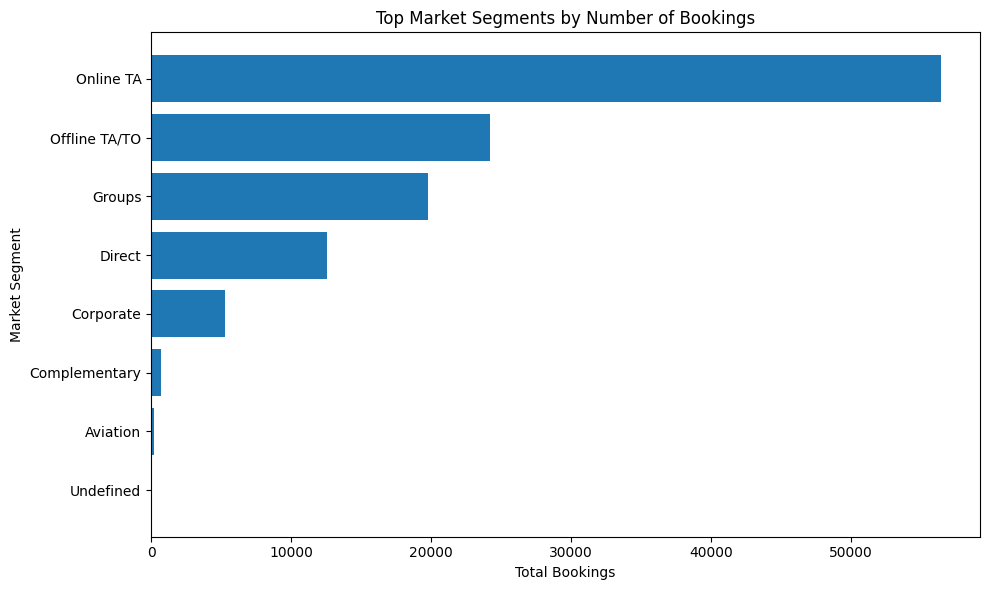

In [27]:
# Visualization 3: Market Segment Rankings

top_segments = query3.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_segments["market_segment"],
    top_segments["total_bookings"]
)

plt.title("Top Market Segments by Number of Bookings")
plt.xlabel("Total Bookings")
plt.ylabel("Market Segment")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

**Query 3 Finding:** Online travel agencies (Online TA) represent the largest market segment, accounting for 56,408 bookings (47.32%). Offline travel agencies and tour operators follow with 24,182 bookings (20.29%), while group bookings account for 19,790 (16.60%). These findings indicate that travel agencies are major booking channels in the dataset.

### Query 4: Average Lead Time by Cancellation Status

**Business Question:** How does average booking lead time differ between canceled and non-canceled bookings across hotel types?

**Method:** Calculate the average number of days between booking entry and scheduled arrival for canceled and non-canceled bookings, grouped by hotel type.

This analysis helps identify whether bookings made further in advance are associated with higher cancellation rates.

In [28]:
# Query 4: Average Lead Time by Cancellation Status

query4 = con.execute("""
SELECT
    h.hotel_type,

    CASE
        WHEN f.is_canceled = 1 THEN 'Canceled'
        ELSE 'Not Canceled'
    END AS cancellation_status,

    COUNT(*) AS total_bookings,

    ROUND(AVG(f.lead_time), 2) AS average_lead_time

FROM hotel_lake.gold.fact_bookings f

JOIN hotel_lake.gold.dim_hotel h
    ON f.hotel_key = h.hotel_key

GROUP BY
    h.hotel_type,
    f.is_canceled

ORDER BY
    h.hotel_type,
    f.is_canceled
""").df()

display(query4)

,hotel_type,cancellation_status,total_bookings,average_lead_time
0,City Hotel,Not Canceled,46084,80.85
1,City Hotel,Canceled,33079,150.33
2,Resort Hotel,Not Canceled,28926,78.85
3,Resort Hotel,Canceled,11120,128.70


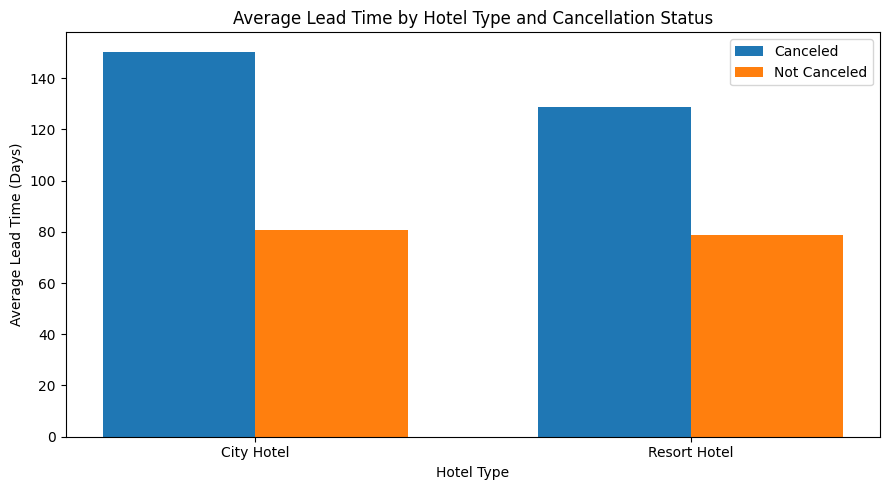

In [29]:
# Visualization 4: Average Lead Time Comparison

import numpy as np

lead_pivot = query4.pivot(
    index="hotel_type",
    columns="cancellation_status",
    values="average_lead_time"
)

x = np.arange(len(lead_pivot.index))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    lead_pivot["Canceled"],
    width,
    label="Canceled"
)

plt.bar(
    x + width / 2,
    lead_pivot["Not Canceled"],
    width,
    label="Not Canceled"
)

plt.xticks(x, lead_pivot.index)
plt.xlabel("Hotel Type")
plt.ylabel("Average Lead Time (Days)")
plt.title("Average Lead Time by Hotel Type and Cancellation Status")
plt.legend()

plt.tight_layout()
plt.show()

**Query 4 Finding:** Canceled bookings have a higher average lead time than non-canceled bookings for both hotel types. For City Hotels, canceled bookings have an average lead time of 150.33 days, compared with 80.85 days for non-canceled bookings. For Resort Hotels, canceled bookings average 128.70 days, compared with 78.85 days for non-canceled bookings. This suggests that bookings made further in advance are associated with a greater likelihood of cancellation, although the results do not establish causation.

## Task 7: Final Pipeline Validation

This section verifies that the Bronze, Silver, and Gold layers contain the expected records and that the pipeline maintains data consistency.

In [30]:

# Final Pipeline Validation

validation = con.execute("""
SELECT
    (SELECT COUNT(*)
     FROM hotel_lake.bronze.hotel_bookings) AS bronze_rows,

    (SELECT COUNT(*)
     FROM hotel_lake.silver.clean_bookings) AS silver_rows,

    (SELECT COUNT(*)
     FROM hotel_lake.silver.quarantined_bookings) AS quarantined_rows,

    (SELECT COUNT(*)
     FROM hotel_lake.gold.fact_bookings) AS gold_rows
""").df()

display(validation)

bronze = int(validation["bronze_rows"].iloc[0])
silver = int(validation["silver_rows"].iloc[0])
quarantined = int(validation["quarantined_rows"].iloc[0])
gold = int(validation["gold_rows"].iloc[0])

assert bronze == 119390
assert silver + quarantined == bronze
assert gold == silver

print("All final pipeline validations passed!")


,bronze_rows,silver_rows,quarantined_rows,gold_rows
0,119390,119209,181,119209


All final pipeline validations passed!


## Task 8: Conclusion

This project successfully implemented a hotel booking data pipeline using DuckDB and DuckLake following the Medallion Architecture.

The Bronze layer ingested 119,390 raw booking records from two hotel datasets. The Silver layer applied data quality checks and transformations, resulting in 119,209 clean records and 181 quarantined records. The Gold layer organized the clean data into a dimensional model for analytical queries.

Four analytical queries were performed to investigate hotel cancellation rates, monthly average daily rates, market segments, and booking lead times.

The results showed that City Hotels experienced higher cancellation rates than Resort Hotels, resort room rates varied significantly by month, online travel agencies represented the largest booking segment, and canceled bookings generally had longer lead times.

Final validation confirmed that the record counts were consistent across the Bronze, Silver, and Gold layers.

Overall, the project demonstrates how a structured data pipeline can transform raw hotel booking data into reliable, analysis-ready information.